# TP 3 — Prompting : utiliser un LLM sans l'entraîner

**Cours NLP et Transformers — CY Tech · Séance 2**

---

## Objectif

Construire un pipeline complet sur **Tiny Shakespeare** avec un modèle de langage pré-entraîné, en quatre étapes (slide 89) :

1. **prompting** : décrire la tâche dans le contexte du modèle ;
2. **modèle LLM** : charger un petit LLM instructionnel et comprendre ce qu'il calcule ;
3. **sortie générée** : transformer le texte produit en décision exploitable ;
4. **évaluation** : mesurer, comparer, chiffrer le coût.

## Fil conducteur

Mêmes données, même tâche et **même jeu de test** que les TP 1 et 2 : retrouver lequel des 5 personnages les plus bavards prononce une réplique. Cette fois, on **n'entraîne rien** : on écrit des consignes (slides 73–75).

Deux questions :

- **Classifier** : un LLM qui n'a vu aucun exemple étiqueté (ou seulement 10) rivalise-t-il avec la régression logistique entraînée sur 516 répliques ?
- **Générer** : le LLM sait-il écrire une réplique « à la manière de » Roméo ou Petruchio, et comment le vérifier ?

## Le modèle

**Qwen2.5-1.5B-Instruct** : un LLM à poids ouverts (licence Apache 2.0, sans compte Hugging Face), de type décodeur (slide 62), assez petit pour tourner sur le GPU gratuit de Colab. Il se télécharge automatiquement (≈ 3 Go).

> **Avant de commencer :** `Exécution → Modifier le type d'exécution → GPU T4`. Avec le GPU, tout le notebook tourne en une dizaine de minutes. Sans GPU, il fonctionne mais beaucoup plus lentement : la validation est alors limitée à 30 répliques.

## Protocole

- Les **exemples few-shot** sont tirés du train ; le choix du prompt se fait sur la **validation** ; le **test** ne sert qu'une fois, à la fin. C'est le même protocole qu'au TP 2.
- Décodage **glouton** (on prend toujours le token le plus probable) pour la classification : la réponse doit être stable et reproductible (slide 78).
- Métrique principale : **F1 macro**, comme aux TP 1 et 2.

## 0. Environnement

In [1]:
import re
import time
import random
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"transformers {transformers.__version__} · PyTorch {torch.__version__} · calcul sur : {device}")
if device.type == "cpu":
    print("⚠️  Pas de GPU : Exécution → Modifier le type d'exécution → GPU T4, puis relancer.")

transformers 5.20.2 · PyTorch 2.11.0+cu130 · calcul sur : cuda


In [2]:
# Style commun des graphiques : fond clair, grille discrète, couleurs lisibles par les daltoniens
SURFACE, INK, INK2, MUTED, GRILLE, AXE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # bleu, orange, aqua
RAMPE_BLEUE = ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK2, "xtick.color": AXE, "ytick.color": AXE,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "lines.linewidth": 2,
    "legend.frameon": False, "legend.labelcolor": INK2, "font.size": 10,
})

## 1. Données : la tâche et le découpage du TP 2

Même corpus, même sélection (5 locuteurs, répliques d'au moins 5 mots), même découpage train / validation / test que le TP 2. Le test est donc celui des TP 1 et 2.

In [3]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte) — fonction du TP 1."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()
top_locuteurs = df["locuteur"].value_counts().head(5).index
donnees = (df[df["locuteur"].isin(top_locuteurs) & (df["n_mots"] >= 5)]
           .loc[:, ["replique", "locuteur"]].reset_index(drop=True))

# Découpage identique au TP 2 : test du TP 1, puis 15 % du reste en validation
X_trval, X_test, y_trval, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"], test_size=0.20,
    stratify=donnees["locuteur"], random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.15, stratify=y_trval, random_state=RANDOM_STATE)

CLASSES = np.array(sorted(y_train.unique()))
K = len(CLASSES)
print(f"train : {len(X_train)}   validation : {len(X_val)}   test : {len(X_test)}")
print(f"Locuteurs : {list(CLASSES)}")

train : 516   validation : 92   test : 153
Locuteurs : [np.str_('DUKE VINCENTIO'), np.str_('GLOUCESTER'), np.str_('MENENIUS'), np.str_('PETRUCHIO'), np.str_('ROMEO')]


## 2. La référence classique

Pour comparer sur les mêmes données, on réentraîne ici la régression logistique sur TF–IDF des TP 1 et 2. Son hyperparamètre `C` est choisi sur la validation. Ses scores de test ne seront regardés qu'à la partie 7.

In [4]:
def nouveau_tfidf(**options):
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.8,
                           sublinear_tf=True, **options)


def nouvelle_lr(C):
    return LogisticRegression(C=C, max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)


vectoriseur = nouveau_tfidf()
Xtr = vectoriseur.fit_transform(X_train)
Xva, Xte = vectoriseur.transform(X_val), vectoriseur.transform(X_test)

scores_C = {C: f1_score(y_val, nouvelle_lr(C).fit(Xtr, y_train).predict(Xva), average="macro")
            for C in [0.5, 1, 2, 5, 10, 20]}
C_LR = max(scores_C, key=scores_C.get)
lr = nouvelle_lr(C_LR).fit(Xtr, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)

print(f"Régression logistique : C = {C_LR}  ->  F1 macro validation = {scores_C[C_LR]:.3f}")

Régression logistique : C = 5  ->  F1 macro validation = 0.618


## 3. Le modèle LLM

### 3.1 Charger le tokenizer et le modèle

Un LLM, ce sont deux objets : le **tokenizer** (texte → identifiants de tokens) et le **réseau** (identifiants → logits du prochain token). En float16 sur GPU, le modèle occupe environ 3 Go de mémoire.

In [5]:
MODELE = "Qwen/Qwen2.5-1.5B-Instruct"
# Autres choix possibles : "Qwen/Qwen2.5-3B-Instruct" (meilleur, ~7 Go de mémoire GPU)
#                          "Qwen/Qwen2.5-0.5B-Instruct" (plus faible, mais rapide même sans GPU)

precision_calcul = torch.float16 if device.type == "cuda" else torch.float32
tok = AutoTokenizer.from_pretrained(MODELE)
try:
    llm = AutoModelForCausalLM.from_pretrained(MODELE, dtype=precision_calcul)
except TypeError:                      # versions plus anciennes de transformers
    llm = AutoModelForCausalLM.from_pretrained(MODELE, torch_dtype=precision_calcul)
llm = llm.to(device).eval()

n_param_llm = sum(p.numel() for p in llm.parameters())
print(f"{MODELE}")
print(f"  {n_param_llm / 1e9:.2f} milliard de paramètres · vocabulaire de {len(tok):,} tokens")
print(f"  {llm.config.num_hidden_layers} blocs Transformer · {llm.config.num_attention_heads} têtes d'attention "
      f"· embeddings de dimension {llm.config.hidden_size}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct
  1.54 milliard de paramètres · vocabulaire de 151,665 tokens
  28 blocs Transformer · 12 têtes d'attention · embeddings de dimension 1536


### 3.2 Ce que calcule le modèle : une distribution sur le prochain token

Un modèle instructionnel attend une **conversation** au format de son entraînement : des messages balisés par rôle (`system`, `user`, `assistant`, slide 80). Le *chat template* du tokenizer produit ce format.

À partir du texte complet, le réseau renvoie des **logits** de forme `(1, T, |V|)` : un score par token du vocabulaire, pour chaque position. Le dernier vecteur, passé dans une softmax, donne la distribution du prochain token (cours Transformers, slides 26–28).

In [6]:
messages = [{"role": "user", "content": "Complete with one word only: To be, or not to"}]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
print("Texte réellement envoyé au modèle :\n" + prompt)

entree = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
print(f"{entree['input_ids'].shape[1]} tokens. Les premiers : {tok.convert_ids_to_tokens(entree['input_ids'][0, :10].tolist())}")

with torch.no_grad():
    logits = llm(**entree).logits
print(f"\nForme des logits : {tuple(logits.shape)} = (batch, positions, vocabulaire)")

probas = torch.softmax(logits[0, -1].float(), dim=-1)
top = torch.topk(probas, 8)
print("\nProchain token le plus probable :")
for p, i in zip(top.values.tolist(), top.indices.tolist()):
    print(f"  {tok.decode([i])!r:<14} {p:.3f}")

Texte réellement envoyé au modèle :
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Complete with one word only: To be, or not to<|im_end|>
<|im_start|>assistant

41 tokens. Les premiers : ['<|im_start|>', 'system', 'Ċ', 'You', 'Ġare', 'ĠQ', 'wen', ',', 'Ġcreated', 'Ġby']

Forme des logits : (1, 41, 151936) = (batch, positions, vocabulaire)

Prochain token le plus probable :
  'to'           0.484
  'To'           0.307
  'be'           0.175
  'not'          0.022
  'exist'        0.003
  'Be'           0.002
  'aim'          0.002
  'live'         0.001


## 4. Prompting

### 4.1 Les briques du prompt

Un bon prompt est une **spécification testable** (slide 82) : objectif, contexte, contraintes, format, exemples. On construit quatre variantes en croisant deux briques, pour mesurer l'effet de chacune séparément :

| | sans exemples | avec 10 exemples (2 par locuteur) |
|---|---|---|
| **sans contexte** | A. zero-shot | C. few-shot |
| **avec contexte** (qui est chaque personnage) | B. zero-shot + contexte | D. few-shot + contexte |

Choix communs à toutes les variantes :

- **Prompt en anglais**, la langue des répliques : un petit modèle suit mieux une consigne rédigée dans la langue du texte qu'il analyse.
- **Liste fermée de réponses** et format imposé (« le nom seul »), pour que la sortie soit exploitable automatiquement.
- **Réplique délimitée** par des balises `<line>…</line>` : c'est une donnée à analyser, jamais une instruction à suivre (slide 80).
- Le **contexte** décrit chaque personnage : pièce, rôle, interlocuteurs habituels. C'est de la connaissance générale sur les pièces ; elle n'est tirée ni de la validation ni du test.
- Les **exemples few-shot** viennent du train, sont courts (6 à 25 mots) et présentés dans un ordre mélangé, pour que le modèle n'associe pas une position à un locuteur (slide 81).

In [7]:
NOMS = {"DUKE VINCENTIO": "Duke Vincentio", "GLOUCESTER": "Gloucester", "MENENIUS": "Menenius",
        "PETRUCHIO": "Petruchio", "ROMEO": "Romeo"}
assert set(NOMS) == set(CLASSES)
LISTE = ", ".join(NOMS[c] for c in CLASSES)

CONSIGNE = ("You identify which Shakespeare character speaks a given line. "
            f"The only possible answers are: {LISTE}. "
            "Answer with the character's name only, nothing else.")

CONTEXTE = """Who the characters are:
- Duke Vincentio (Measure for Measure): the Duke of Vienna, who disguises himself as a friar; he deals with Angelo, Escalus, Claudio, Isabella, Lucio and the Provost.
- Gloucester (Henry VI Part 3, Richard III): Richard, Duke of Gloucester, later King Richard III; ambitious and scheming; he speaks of his brothers King Edward and Clarence, of Warwick, Buckingham and the crown.
- Menenius (Coriolanus): Menenius Agrippa, an old patrician of Rome and mentor of Caius Marcius (Coriolanus); he jokes with the citizens and quarrels with the tribunes Sicinius and Brutus.
- Petruchio (The Taming of the Shrew): a boisterous, witty gentleman of Verona who woos and tames Katherina (Kate); he speaks with Hortensio, Baptista and his servant Grumio.
- Romeo (Romeo and Juliet): the young lover of Juliet; lyrical speeches about love, night, light and death; he speaks with Mercutio, Benvolio, Friar Laurence and the Nurse."""


def message_utilisateur(replique):
    return f"Which character speaks this line?\n<line>{replique}</line>"


# Exemples few-shot : 2 par locuteur, tirés du train uniquement
rng = random.Random(RANDOM_STATE)
EXEMPLES = []
for c in CLASSES:
    candidats = [r for r, y in zip(X_train, y_train) if y == c and 6 <= len(r.split()) <= 25]
    EXEMPLES += [(r, c) for r in rng.sample(candidats, 2)]
rng.shuffle(EXEMPLES)


def construire_messages(replique, contexte=False, exemples=False):
    systeme = CONSIGNE + ("\n\n" + CONTEXTE if contexte else "")
    messages = [{"role": "system", "content": systeme}]
    if exemples:
        for r, c in EXEMPLES:
            messages += [{"role": "user", "content": message_utilisateur(r)},
                         {"role": "assistant", "content": NOMS[c]}]
    messages.append({"role": "user", "content": message_utilisateur(replique)})
    return messages


VARIANTES = {
    "A. zero-shot":            dict(contexte=False, exemples=False),
    "B. zero-shot + contexte": dict(contexte=True, exemples=False),
    "C. few-shot":             dict(contexte=False, exemples=True),
    "D. few-shot + contexte":  dict(contexte=True, exemples=True),
}


def n_tokens(messages):
    return len(tok(tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True),
                   add_special_tokens=False)["input_ids"])


exemple_val = X_val.iloc[0]
print("Taille du prompt complet (pour la première réplique de validation) :")
for nom, options in VARIANTES.items():
    print(f"  {nom:<25} {n_tokens(construire_messages(exemple_val, **options)):>5} tokens")

Taille du prompt complet (pour la première réplique de validation) :
  A. zero-shot                120 tokens
  B. zero-shot + contexte     370 tokens
  C. few-shot                 547 tokens
  D. few-shot + contexte      797 tokens


Le prompt complet de la variante B, tel que le modèle le reçoit :

In [8]:
print(tok.apply_chat_template(construire_messages(exemple_val, contexte=True), tokenize=False,
                              add_generation_prompt=True))

<|im_start|>system
You identify which Shakespeare character speaks a given line. The only possible answers are: Duke Vincentio, Gloucester, Menenius, Petruchio, Romeo. Answer with the character's name only, nothing else.

Who the characters are:
- Duke Vincentio (Measure for Measure): the Duke of Vienna, who disguises himself as a friar; he deals with Angelo, Escalus, Claudio, Isabella, Lucio and the Provost.
- Gloucester (Henry VI Part 3, Richard III): Richard, Duke of Gloucester, later King Richard III; ambitious and scheming; he speaks of his brothers King Edward and Clarence, of Warwick, Buckingham and the crown.
- Menenius (Coriolanus): Menenius Agrippa, an old patrician of Rome and mentor of Caius Marcius (Coriolanus); he jokes with the citizens and quarrels with the tribunes Sicinius and Brutus.
- Petruchio (The Taming of the Shrew): a boisterous, witty gentleman of Verona who woos and tames Katherina (Kate); he speaks with Hortensio, Baptista and his servant Grumio.
- Romeo (Ro

## 5. De la sortie générée à une décision

Le modèle produit du **texte libre**. Pour l'évaluer, il faut en tirer l'un des 5 locuteurs. On compare deux façons de faire, à partir du même appel :

1. **Génération libre, puis lecture.** Le modèle génère jusqu'à 10 tokens en décodage glouton ; on cherche dans le texte le nom d'un des 5 personnages. Si on n'en trouve aucun, ou plusieurs, la réponse est **invalide** : c'est le risque de format du pipeline LLM (slide 74, étape « contrôler »).
2. **Choix contraint par les logits.** On lit directement la distribution du **premier token** de la réponse, restreinte aux 5 tokens par lesquels commencent les noms autorisés, et on prend le plus probable. La réponse est toujours valide, et on obtient au passage une probabilité par locuteur.

La génération gloutonne prend le token le plus probable **parmi tout le vocabulaire** ; le choix contraint, le plus probable **parmi les 5 réponses permises**. Les deux coïncident dès que le modèle respecte le format.

In [9]:
PREMIER_TOKEN = {c: tok.encode(NOMS[c], add_special_tokens=False)[0] for c in CLASSES}
assert len(set(PREMIER_TOKEN.values())) == K, \
    "Deux noms commencent par le même token : il faudrait scorer les noms complets."
print("Premier token de chaque réponse autorisée :",
      {NOMS[c]: tok.convert_ids_to_tokens(i) for c, i in PREMIER_TOKEN.items()})
IDS_CANDIDATS = torch.tensor([PREMIER_TOKEN[c] for c in CLASSES], device=device)

MOTS_CLES = {"DUKE VINCENTIO": ["vincentio"], "GLOUCESTER": ["gloucester"], "MENENIUS": ["menenius"],
             "PETRUCHIO": ["petruchio"], "ROMEO": ["romeo"]}


def lire_reponse(genere):
    """Texte généré -> locuteur, ou None si aucun nom (ou plusieurs) n'est reconnu."""
    t = genere.lower()
    trouves = [c for c in CLASSES if any(m in t for m in MOTS_CLES[c])]
    return trouves[0] if len(trouves) == 1 else None


@torch.no_grad()
def interroger(messages, max_new_tokens=10):
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    entree = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    t0 = time.perf_counter()

    # 1) Choix contraint : distribution du prochain token, restreinte aux 5 réponses autorisées
    logits = llm(**entree).logits[0, -1].float()
    p5 = torch.softmax(logits[IDS_CANDIDATS], dim=-1).cpu().numpy()

    # 2) Génération libre, gloutonne (do_sample=False : toujours le token le plus probable)
    sortie = llm.generate(**entree, max_new_tokens=max_new_tokens, do_sample=False,
                          temperature=None, top_p=None, top_k=None,
                          pad_token_id=tok.pad_token_id or tok.eos_token_id)
    genere = tok.decode(sortie[0, entree["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    return {"contraint": CLASSES[p5.argmax()], "confiance": float(p5.max()), "généré": genere,
            "lu": lire_reponse(genere), "tokens": entree["input_ids"].shape[1],
            "secondes": time.perf_counter() - t0}


r = interroger(construire_messages(exemple_val, contexte=True))
print(f"\nRéplique : « {exemple_val[:120]} »\nVrai locuteur : {y_val.iloc[0]}")
print(f"Texte généré : {r['généré']!r} -> lu comme {r['lu']}")
print(f"Choix contraint : {r['contraint']} (probabilité {r['confiance']:.2f})")

Premier token de chaque réponse autorisée : {'Duke Vincentio': 'D', 'Gloucester': 'Gl', 'Menenius': 'Men', 'Petruchio': 'P', 'Romeo': 'R'}

Réplique : « 'Tis good; though music oft hath such a charm To make bad good, and good provoke to harm. I pray, you, tell me, hath any »
Vrai locuteur : DUKE VINCENTIO
Texte généré : 'Petruchio' -> lu comme PETRUCHIO
Choix contraint : PETRUCHIO (probabilité 0.59)


## 6. Choisir le prompt sur la validation

Chaque variante est évaluée sur la validation. Une réponse invalide compte comme une erreur. On regarde aussi le **coût** : longueur du prompt et temps par réplique.

In [10]:
N_VAL = None if device.type == "cuda" else 30      # sans GPU : 30 répliques seulement
X_val_eval, y_val_eval = X_val.iloc[:N_VAL], y_val.iloc[:N_VAL]


def evaluer(X, options):
    return pd.DataFrame([interroger(construire_messages(r, **options)) for r in X])


def f1_macro(y_vrai, y_pred):
    """Les réponses invalides (None) comptent comme des erreurs."""
    y_pred = ["INVALIDE" if p is None else p for p in y_pred]
    return f1_score(y_vrai, y_pred, labels=list(CLASSES), average="macro", zero_division=0)


resultats_val, lignes = {}, []
for nom, options in VARIANTES.items():
    t0 = time.perf_counter()
    res = evaluer(X_val_eval, options)
    resultats_val[nom] = res
    lignes.append({
        "variante": nom,
        "F1 macro (choix contraint)": f1_macro(y_val_eval, res["contraint"]),
        "F1 macro (génération lue)": f1_macro(y_val_eval, res["lu"]),
        "réponses invalides": res["lu"].isna().mean(),
        "tokens par prompt": res["tokens"].mean(),
        "secondes par réplique": res["secondes"].mean(),
    })
    print(f"{nom:<25} terminé en {time.perf_counter() - t0:.0f} s")

table_val = pd.DataFrame(lignes).set_index("variante")
MEILLEURE = table_val["F1 macro (choix contraint)"].idxmax()
print(f"\nVariante retenue (meilleur F1 macro contraint sur la validation) : {MEILLEURE}")
print(f"Pour comparaison, régression logistique sur la même validation : "
      f"F1 = {f1_score(y_val_eval, lr.predict(vectoriseur.transform(X_val_eval)), average='macro'):.3f}")
table_val.round(3)

A. zero-shot              terminé en 37 s
B. zero-shot + contexte   terminé en 32 s
C. few-shot               terminé en 41 s
D. few-shot + contexte    terminé en 59 s

Variante retenue (meilleur F1 macro contraint sur la validation) : D. few-shot + contexte
Pour comparaison, régression logistique sur la même validation : F1 = 0.618


,F1 macro (choix contraint),F1 macro (génération lue),réponses invalides,tokens par prompt,secondes par réplique
variante,,,,,
A. zero-shot,0.268,0.273,0.043,113.152,0.401
B. zero-shot + contexte,0.302,0.274,0.065,363.152,0.345
C. few-shot,0.363,0.333,0.130,540.152,0.443
D. few-shot + contexte,0.409,0.356,0.217,790.152,0.641


**Comment lire ce tableau.**

- **B − A** mesure l'apport du contexte, **C − A** celui des exemples, **D** leur combinaison. Le contexte fournit au modèle des indices précis (Kate et Hortensio pour Petruchio, Clarence pour Gloucester…), là où le zero-shot ne peut compter que sur ce que le modèle a retenu des pièces pendant son pré-entraînement.
- Chaque exemple few-shot ajoute des tokens : le prompt s'allonge, donc chaque appel coûte plus cher en temps (slide 79). Le gain doit justifier ce coût.
- **Un écart entre les deux colonnes de F1 signale des problèmes de format** : le modèle répond autre chose qu'un nom de la liste. Le choix contraint, lui, ne peut pas sortir du format.
- La validation ne compte que 92 répliques : un écart de 0,02 à 0,03 entre deux variantes n'est pas significatif.

In [11]:
# Biais de réponse : quels noms le modèle donne-t-il, par rapport à la vraie répartition ?
repartition = pd.DataFrame({"vraie répartition": y_val_eval.value_counts()}).reindex(CLASSES)
for nom, res in resultats_val.items():
    repartition[nom] = res["contraint"].value_counts().reindex(CLASSES)
print("Nombre de réponses par locuteur sur la validation (choix contraint)")
print(repartition.fillna(0).astype(int).to_string(), "\n")

invalides = [(nom, x, g) for nom, res in resultats_val.items()
             for x, g, l in zip(X_val_eval, res["généré"], res["lu"]) if l is None]
print(f"{len(invalides)} réponses générées invalides au total. Exemples :")
for nom, x, g in invalides[:6]:
    print(f"  [{nom}] « {x[:60]}… » -> {g!r}")

Nombre de réponses par locuteur sur la validation (choix contraint)
                vraie répartition  A. zero-shot  B. zero-shot + contexte  C. few-shot  D. few-shot + contexte
locuteur                                                                                                     
DUKE VINCENTIO                 20            11                       37           24                      20
GLOUCESTER                     24             9                        4           18                       8
MENENIUS                       15            14                        8           39                      19
PETRUCHIO                      16            23                       22            4                      12
ROMEO                          17            35                       21            7                      33 

42 réponses générées invalides au total. Exemples :
  [A. zero-shot] « Born in Verona, old Antonio's son: My father dead, my fortun… » -> 'Antonio'
  [A. zero-s

Un LLM a souvent un **biais de réponse** : il répond trop souvent le personnage le plus célèbre ou celui qui est cité en premier dans la liste. Une colonne très éloignée de la vraie répartition le révèle, et explique une partie des erreurs. Les réponses invalides montrent pourquoi un pipeline LLM a besoin d'une étape de **contrôle du format** (slide 74).

## 7. Évaluation finale sur le test

Le prompt est choisi : on l'applique au test, une seule fois, et on compare à la référence classique.

In [12]:
t0 = time.perf_counter()
res_test = evaluer(X_test, VARIANTES[MEILLEURE])
print(f"{len(X_test)} répliques de test interrogées en {time.perf_counter() - t0:.0f} s ({MEILLEURE})\n")

t0 = time.perf_counter()
pred_lr = lr.predict(vectoriseur.transform(X_test))
sec_lr = (time.perf_counter() - t0) / len(X_test)
proba_lr_test = lr.predict_proba(vectoriseur.transform(X_test)).max(1)


def metriques(y_vrai, y_pred):
    y_pred = ["INVALIDE" if p is None else p for p in y_pred]
    kw = dict(labels=list(CLASSES), average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_vrai, y_pred), "précision (macro)": precision_score(y_vrai, y_pred, **kw),
            "rappel (macro)": recall_score(y_vrai, y_pred, **kw), "F1 (macro)": f1_score(y_vrai, y_pred, **kw)}


n_exemples_prompt = len(EXEMPLES) if VARIANTES[MEILLEURE]["exemples"] else 0
comparaison = pd.DataFrame({
    "Baseline (classe majoritaire)": {**metriques(y_test, baseline.predict(Xte)),
                                      "répliques annotées utilisées": len(X_train), "secondes par réplique": 0.0},
    "Régression logistique (TF–IDF)": {**metriques(y_test, pred_lr),
                                       "répliques annotées utilisées": len(X_train), "secondes par réplique": sec_lr},
    f"LLM — génération lue ({MEILLEURE})": {**metriques(y_test, res_test["lu"]),
                                             "répliques annotées utilisées": n_exemples_prompt,
                                             "secondes par réplique": res_test["secondes"].mean()},
    f"LLM — choix contraint ({MEILLEURE})": {**metriques(y_test, res_test["contraint"]),
                                              "répliques annotées utilisées": n_exemples_prompt,
                                              "secondes par réplique": res_test["secondes"].mean()},
}).T
print(f"Réponses générées invalides sur le test : {res_test['lu'].isna().mean():.1%}")
print(f"Paramètres : régression logistique {lr.coef_.size + lr.intercept_.size:,} · LLM {n_param_llm:,}")
comparaison.round(4)

153 répliques de test interrogées en 90 s (D. few-shot + contexte)

Réponses générées invalides sur le test : 21.6%
Paramètres : régression logistique 14,795 · LLM 1,543,714,304


,accuracy,précision (macro),rappel (macro),F1 (macro),répliques annotées utilisées,secondes par réplique
Baseline (classe majoritaire),0.2614,0.0523,0.2000,0.0829,516.0,0.0000
Régression logistique (TF–IDF),0.6340,0.6365,0.6285,0.6317,516.0,0.0001
LLM — génération lue (D. few-shot + contexte),0.3595,0.5283,0.3701,0.4071,10.0,0.5829
LLM — choix contraint (D. few-shot + contexte),0.4510,0.4951,0.4656,0.4485,10.0,0.5829


### 7.1 Une approche hybride : le LLM en renfort

Le modèle classique est rapide mais se trompe surtout quand il hésite ; le LLM est lent mais ne dépend pas des mêmes indices. D'où l'idée **hybride** de la slide 75 : on garde la réponse de la régression logistique quand elle est sûre d'elle (probabilité maximale ≥ un seuil), et on interroge le LLM sinon. Le seuil est choisi sur la validation.

In [13]:
def hybride(pred_lr, conf_lr, pred_llm, seuil):
    return np.where(conf_lr >= seuil, pred_lr, pred_llm)


Xv = vectoriseur.transform(X_val_eval)
pred_lr_val, conf_lr_val = lr.predict(Xv), lr.predict_proba(Xv).max(1)
pred_llm_val = resultats_val[MEILLEURE]["contraint"].to_numpy()

seuils = np.round(np.arange(0.20, 0.96, 0.05), 2)
f1_seuils = {s: f1_score(y_val_eval, hybride(pred_lr_val, conf_lr_val, pred_llm_val, s), average="macro")
             for s in seuils}
SEUIL = max(f1_seuils, key=f1_seuils.get)

pred_hyb = hybride(pred_lr, proba_lr_test, res_test["contraint"].to_numpy(), SEUIL)
part_llm = np.mean(proba_lr_test < SEUIL)
comparaison.loc[f"Hybride (LR si confiance ≥ {SEUIL}, sinon LLM)"] = pd.Series({
    **metriques(y_test, pred_hyb), "répliques annotées utilisées": len(X_train),
    "secondes par réplique": sec_lr + part_llm * res_test["secondes"].mean()})

print(f"Seuil retenu sur la validation : {SEUIL}  ->  le LLM traite {part_llm:.0%} des répliques de test")
comparaison.round(4)

Seuil retenu sur la validation : 0.4  ->  le LLM traite 39% des répliques de test


,accuracy,précision (macro),rappel (macro),F1 (macro),répliques annotées utilisées,secondes par réplique
Baseline (classe majoritaire),0.2614,0.0523,0.2000,0.0829,516.0,0.0000
Régression logistique (TF–IDF),0.6340,0.6365,0.6285,0.6317,516.0,0.0001
LLM — génération lue (D. few-shot + contexte),0.3595,0.5283,0.3701,0.4071,10.0,0.5829
LLM — choix contraint (D. few-shot + contexte),0.4510,0.4951,0.4656,0.4485,10.0,0.5829
"Hybride (LR si confiance ≥ 0.4, sinon LLM)",0.6536,0.6656,0.6595,0.6545,516.0,0.2287


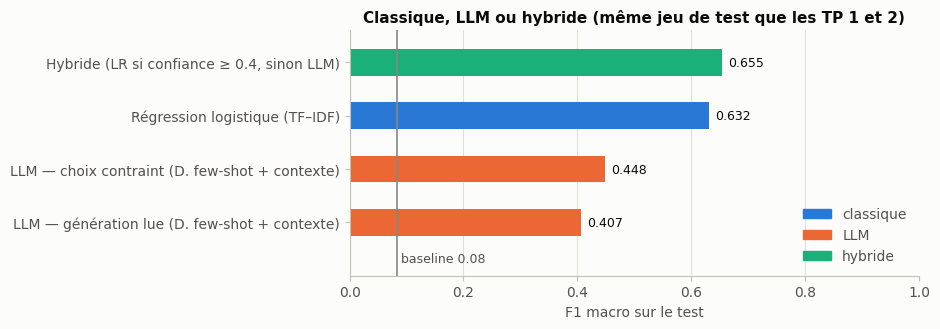

In [14]:
t = comparaison.drop(index="Baseline (classe majoritaire)").sort_values("F1 (macro)")
famille = ["hybride" if n.startswith("Hybride") else "LLM" if n.startswith("LLM") else "classique" for n in t.index]
couleur = {"classique": SERIES[0], "LLM": SERIES[1], "hybride": SERIES[2]}
y = np.arange(len(t))

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.barh(y, t["F1 (macro)"], height=0.5, color=[couleur[f] for f in famille])
for yi, v in enumerate(t["F1 (macro)"]):
    ax.text(v + 0.01, yi, f"{v:.3f}", va="center", color=INK, fontsize=9)
base = comparaison.loc["Baseline (classe majoritaire)", "F1 (macro)"]
ax.axvline(base, color=MUTED, linewidth=1.2)
ax.text(base + 0.008, -0.75, f"baseline {base:.2f}", color=INK2, fontsize=9)
ax.set_yticks(y, t.index)
ax.set_ylim(-1, len(t) - 0.4)
ax.set_xlim(0, 1)
ax.set_xlabel("F1 macro sur le test")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=couleur[f], label=f) for f in ["classique", "LLM", "hybride"]], loc="lower right")
ax.set_title("Classique, LLM ou hybride (même jeu de test que les TP 1 et 2)")
plt.tight_layout()
plt.show()

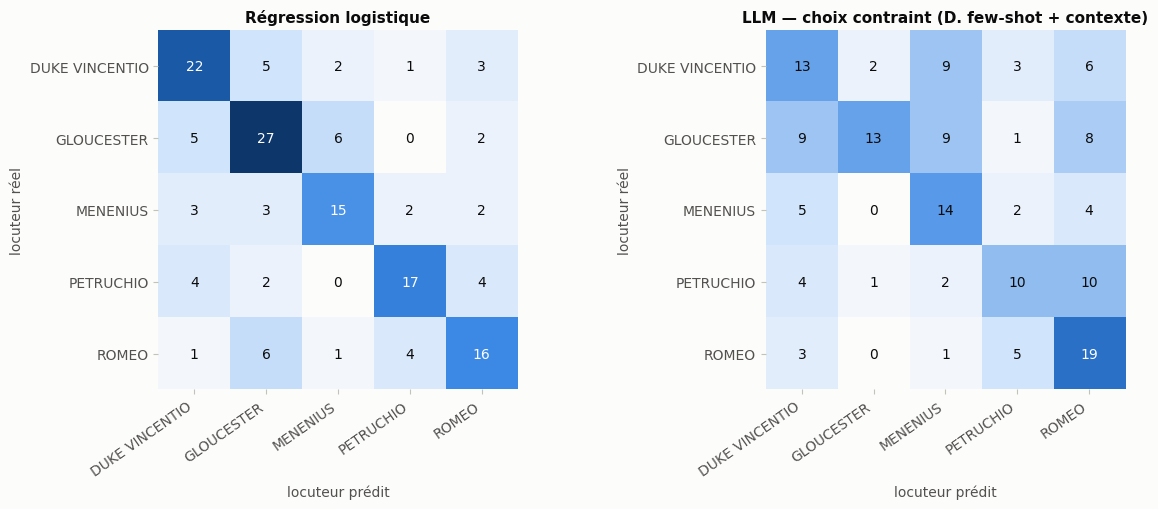

In [15]:
carte = LinearSegmentedColormap.from_list("bleu", RAMPE_BLEUE)
cms = [(confusion_matrix(y_test, pred_lr, labels=CLASSES), "Régression logistique"),
       (confusion_matrix(y_test, res_test["contraint"], labels=CLASSES), f"LLM — choix contraint ({MEILLEURE})")]
vmax = max(cm.max() for cm, _ in cms)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, (cm, titre) in zip(axes, cms):
    ax.imshow(cm, cmap=carte, vmin=0, vmax=vmax)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                    color="#ffffff" if cm[i, j] > 0.55 * vmax else INK)
    ax.set_xticks(range(K), CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(K), CLASSES)
    ax.set_xlabel("locuteur prédit")
    ax.set_ylabel("locuteur réel")
    ax.set_title(titre)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
plt.tight_layout()
plt.show()

In [16]:
# Lecture automatique des résultats principaux
base = comparaison.loc["Baseline (classe majoritaire)", "F1 (macro)"]
f1_lr = comparaison.loc["Régression logistique (TF–IDF)", "F1 (macro)"]
f1_llm = comparaison.loc[f"LLM — choix contraint ({MEILLEURE})", "F1 (macro)"]
f1_gen = comparaison.loc[f"LLM — génération lue ({MEILLEURE})", "F1 (macro)"]
f1_hyb = comparaison.filter(like="Hybride", axis=0)["F1 (macro)"].iloc[0]
ratio_temps = res_test["secondes"].mean() / max(sec_lr, 1e-9)

print(f"• LLM (choix contraint) : F1 {f1_llm:.3f} contre {f1_lr:.3f} pour la régression logistique "
      f"({f1_llm - f1_lr:+.3f}), et {base:.3f} pour la baseline.")
print(f"• Lire la génération plutôt que les logits fait passer le F1 de {f1_llm:.3f} à {f1_gen:.3f} "
      f"({res_test['lu'].isna().mean():.0%} de réponses invalides).")
print(f"• L'hybride obtient {f1_hyb:.3f} ({f1_hyb - f1_lr:+.3f} par rapport à la régression logistique) "
      f"en n'appelant le LLM que sur {part_llm:.0%} des répliques.")
print(f"• Une réplique coûte environ {ratio_temps:,.0f} fois plus de temps au LLM qu'à la régression logistique.")

• LLM (choix contraint) : F1 0.448 contre 0.632 pour la régression logistique (-0.183), et 0.083 pour la baseline.
• Lire la génération plutôt que les logits fait passer le F1 de 0.448 à 0.407 (22% de réponses invalides).
• L'hybride obtient 0.655 (+0.023 par rapport à la régression logistique) en n'appelant le LLM que sur 39% des répliques.
• Une réplique coûte environ 10,088 fois plus de temps au LLM qu'à la régression logistique.


**Comment interpréter la comparaison.**

Pour mémoire, sur ce même jeu de test, le TP 2 obtenait un F1 macro de 0,662 avec Naive Bayes, 0,655 avec le MLP et 0,444 avec le BiLSTM.

- **Le modèle entraîné a un avantage structurel** : il a appris sur 516 répliques étiquetées exactement les indices qui séparent ces 5 personnages, y compris les noms propres de chaque pièce (leçon du TP 1). Le LLM n'a vu au mieux que 10 exemples ; sa seule ressource est ce qu'il sait déjà de Shakespeare et le contexte qu'on lui donne.
- **Si le LLM s'approche de la régression logistique**, c'est qu'il exploite une connaissance acquise au pré-entraînement. Attention à la **contamination** : Shakespeare est presque certainement dans ses données d'entraînement. Le score peut donc refléter de la mémorisation des pièces plutôt qu'une compréhension du style. Sur un corpus inédit (des courriels d'entreprise, par exemple), ce serait différent.
- **La génération lue est en dessous du choix contraint** dès que le modèle sort du format. En production, on corrigerait cela avec une sortie structurée (JSON, liste fermée imposée par l'API) et une validation automatique de la réponse.
- **L'hybride** illustre la conclusion de la slide 75 : on garde le modèle rapide et bon marché pour les cas faciles, et on réserve le modèle coûteux aux cas incertains. Il n'est utile que s'il dépasse la régression logistique seule, puisqu'il coûte plus cher.
- **Le coût** : le LLM a environ 100 000 fois plus de paramètres que la régression logistique et met beaucoup plus de temps par réplique. Sur un gros volume (des millions de messages), cet écart décide souvent du choix, à qualité égale.

## 8. Générer du texte : « à la manière de… »

Jusqu'ici, la génération servait à produire un nom. Utilisons maintenant le LLM pour ce qu'il sait faire de mieux : **écrire**. On lui demande d'inventer une courte réplique pour chacun des 5 personnages.

Pour la création, on **échantillonne** au lieu de prendre toujours le token le plus probable (cours Transformers, slide 6). La **température** règle la diversité, et `top_p` élimine la queue de distribution (slide 78).

**Évaluer un texte généré est difficile** : il n'y a pas de bonne réponse unique. On combine trois mesures automatiques :

1. **Reconnaissance du style** : notre régression logistique attribue-t-elle la réplique générée au bon personnage ? On l'utilise comme *juge*.
2. **Originalité** : part des suites de 6 mots (6-grammes) de la réplique déjà présentes dans le corpus. Un score élevé signale de la **récitation** plutôt que de l'invention.
3. **Diversité** : *distinct-2*, part des paires de mots différentes parmi toutes celles produites pour un personnage. Proche de 1 : variées ; proche de 0 : répétitives.

In [17]:
PIECES = {"DUKE VINCENTIO": "Measure for Measure", "GLOUCESTER": "Richard III", "MENENIUS": "Coriolanus",
          "PETRUCHIO": "The Taming of the Shrew", "ROMEO": "Romeo and Juliet"}


def demande_tirade(c):
    return [
        {"role": "system", "content": "You are a playwright who writes in the style of Shakespeare "
                                      "(Early Modern English, blank verse)."},
        {"role": "user", "content": f"Write a new short speech (3 or 4 lines of verse) that {NOMS[c]} "
                                    f"from {PIECES[c]} could say. Invent new lines: do not quote the play. "
                                    "Answer with the speech only, without the character's name."},
    ]


@torch.no_grad()
def generer(messages, n=5, temperature=0.8, top_p=0.95, max_new_tokens=90, graine=0):
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    entree = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    torch.manual_seed(graine)
    sorties = llm.generate(**entree, do_sample=True, temperature=temperature, top_p=top_p, top_k=None,
                           max_new_tokens=max_new_tokens, num_return_sequences=n,
                           pad_token_id=tok.pad_token_id or tok.eos_token_id)
    debut = entree["input_ids"].shape[1]
    return [tok.decode(s[debut:], skip_special_tokens=True).strip() for s in sorties]


generations = pd.DataFrame([{"personnage": c, "texte": t}
                            for c in CLASSES for t in generer(demande_tirade(c), graine=RANDOM_STATE)])
for c in CLASSES:
    print(f"--- {c} ---\n{generations.loc[generations['personnage'] == c, 'texte'].iloc[0]}\n")

--- DUKE VINCENTIO ---
Now then, you have strayed and wandered far From paths of virtue; take your conscience' warning. Let justice guide you, but avoid such pride That leads to tyrannical might. For true leadership Must stem from love and wisdom, not cruel might. Remember, we act as mirrors for each other's faults And correct them together. So let us mend our ways As one family bound by noble friendship. What more shall I say? Leave what

--- GLOUCESTER ---
Now then, you have striven and faltered both ways; But yet it remains our will to give this place To those who strive for right and noble deeds, Not he who fears less wrong than what they know.
Here’s where we stand, here shall we bear The glory of this fight for justice, And show the world what true courage is. For he hath said, ‘We must not hide,’
And now let others judge their souls

--- MENENIUS ---
Now then, you have striven to fight as brave and bold; yet take it hearken well, for you've played at war too long.
Let's pause th

### 8.1 Mesurer le style, l'originalité et la diversité

Le TP 1 a montré que la régression logistique reconnaît surtout les **noms propres**. Un juge qui accorde « Romeo » dès qu'il lit « Juliet » serait trop facile à satisfaire. On utilise donc **deux juges** : la régression logistique habituelle, et une version entraînée **sans noms propres**, qui ne peut s'appuyer que sur le vocabulaire et le registre.

Un mot est considéré comme nom propre s'il apparaît avec une majuscule, mais jamais en minuscules, dans tout le corpus (même heuristique qu'au TP 2).

In [18]:
capitalises = set(re.findall(r"\b[A-Z][a-z]+\b", texte))
minuscules = set(re.findall(r"\b[a-z]+\b", texte))
NOMS_PROPRES = sorted({m.lower() for m in capitalises if m.lower() not in minuscules})

vec_sans = nouveau_tfidf(stop_words=NOMS_PROPRES)
lr_sans = nouvelle_lr(C_LR).fit(vec_sans.fit_transform(X_train), y_train)

MOTS = re.compile(r"[a-z]+(?:'[a-z]+)*")
mots_corpus = MOTS.findall(texte.lower())
NGRAMMES_CORPUS = {tuple(mots_corpus[i:i + 6]) for i in range(len(mots_corpus) - 5)}


def part_copiee(t, n=6):
    m = MOTS.findall(t.lower())
    grams = [tuple(m[i:i + n]) for i in range(len(m) - n + 1)]
    return np.mean([g in NGRAMMES_CORPUS for g in grams]) if grams else 0.0


def distinct_2(textes):
    paires = [tuple(p) for t in textes for p in zip(MOTS.findall(t.lower()), MOTS.findall(t.lower())[1:])]
    return len(set(paires)) / max(len(paires), 1)


def juger(gen):
    gen = gen.copy()
    gen["juge LR"] = lr.predict(vectoriseur.transform(gen["texte"]))
    gen["juge LR sans noms propres"] = lr_sans.predict(vec_sans.transform(gen["texte"]))
    gen["part de 6-grammes copiés"] = gen["texte"].map(part_copiee)
    gen["mots"] = gen["texte"].map(lambda t: len(t.split()))
    return gen


generations = juger(generations)
bilan = generations.groupby("personnage").agg(
    reconnu_LR=("juge LR", lambda s: np.mean(s == generations.loc[s.index, "personnage"])),
    reconnu_LR_sans_noms=("juge LR sans noms propres", lambda s: np.mean(s == generations.loc[s.index, "personnage"])),
    copie_6grammes=("part de 6-grammes copiés", "mean"),
    mots=("mots", "mean"),
)
bilan["distinct-2"] = [distinct_2(generations.loc[generations["personnage"] == c, "texte"]) for c in bilan.index]
bilan.loc["ENSEMBLE"] = [np.mean(generations["juge LR"] == generations["personnage"]),
                         np.mean(generations["juge LR sans noms propres"] == generations["personnage"]),
                         generations["part de 6-grammes copiés"].mean(), generations["mots"].mean(),
                         distinct_2(generations["texte"])]
print("Taux de reconnaissance par les juges (hasard : 0,20), originalité et diversité")
bilan.round(3)

Taux de reconnaissance par les juges (hasard : 0,20), originalité et diversité


,reconnu_LR,reconnu_LR_sans_noms,copie_6grammes,mots,distinct-2
personnage,,,,,
DUKE VINCENTIO,0.40,0.20,0.0,56.60,0.989
GLOUCESTER,0.20,0.40,0.0,57.40,0.979
MENENIUS,0.40,0.20,0.0,68.40,0.982
PETRUCHIO,0.40,0.40,0.0,65.00,0.966
ROMEO,1.00,1.00,0.0,62.40,0.967
ENSEMBLE,0.48,0.44,0.0,61.96,0.929


**Comment lire ce tableau.**

- **Reconnaissance** : au hasard, un juge reconnaîtrait 20 % des répliques. Si le juge LR reconnaît beaucoup plus de répliques que le juge sans noms propres, le LLM « signe » ses textes en citant les autres personnages de la pièce (Juliet, Kate, Clarence) plutôt qu'en imitant une voix. C'est exactement le raccourci du TP 1, cette fois du côté du générateur.
- **Copie** : une part de 6-grammes copiés proche de 0 indique des vers inventés ; une part élevée, une récitation de la pièce, ce qu'on a explicitement interdit dans la consigne.
- **Limite des juges** : nos juges ont appris sur 516 répliques et ne mesurent ni la qualité littéraire, ni le respect du vers, ni la cohérence. Pour une vraie évaluation, il faudrait une **grille humaine** définie à l'avance (c'est ce que demande le mini-projet 2).

### 8.2 L'effet de la température

Même consigne (une réplique de Roméo), 5 tirages pour trois températures. Une température basse rend la distribution plus « pointue » (les tirages se ressemblent) ; une température haute l'aplatit (plus de diversité, plus de risque d'incohérence).

In [19]:
lignes = []
for temperature in [0.2, 0.8, 1.4]:
    textes = generer(demande_tirade("ROMEO"), temperature=temperature, top_p=1.0, graine=RANDOM_STATE)
    g = juger(pd.DataFrame({"personnage": "ROMEO", "texte": textes}))
    lignes.append({"température": temperature, "distinct-2": distinct_2(textes),
                   "reconnu par le juge LR": np.mean(g["juge LR"] == "ROMEO"),
                   "part de 6-grammes copiés": g["part de 6-grammes copiés"].mean(),
                   "exemple": textes[0].replace("\n", " / ")[:150]})
pd.DataFrame(lignes).set_index("température").round(3)

,distinct-2,reconnu par le juge LR,part de 6-grammes copiés,exemple
température,,,,
0.2,0.921,1.0,0.0,"O fair Verona, sweet youth, where we did spend our days, / Where love was but a word, and kisses were no m..."
0.8,0.951,1.0,0.0,"Now then, you have stricken my heart asunder, breaking its peace within me; now it beats so wildly for lov..."
1.4,1.000,0.4,0.0,Now then let us have straits and outs as must Comedrae אש't helmed when Paeon sounds for spleen Dyn Eisena...


On attend une **diversité (distinct-2) croissante** avec la température. À 0,2, les tirages sont presque identiques, car le modèle choisit presque toujours le même token. À 1,4, le texte devient plus varié mais commence à perdre en cohérence (lisez la colonne « exemple »). C'est pourquoi on conseille un décodage **peu aléatoire pour l'extraction et la classification**, et une température modérée pour la **création** (slide 78).

## 9. Synthèse

| | Pipeline classique (TP 1) | Réseau entraîné (TP 2) | LLM par prompting (TP 3) |
|---|---|---|---|
| **Données annotées** | 516 répliques | 516 répliques | 0 à 10 répliques |
| **Ce qu'il faut concevoir** | représentation, modèle, réglages | architecture, entraînement, arrêt précoce | consignes, contexte, exemples, contrôle du format |
| **Coût par réplique** | négligeable | faible | élevé (milliards de paramètres) |
| **Risques propres** | raccourcis (noms propres), couverture limitée | instabilité, sur-apprentissage, besoin de données | format invalide, biais de réponse, contamination, sensibilité au prompt |
| **Point fort** | rapide, simple, solide sur une tâche étroite | lit l'ordre des mots | aucune annotation, langage ouvert, **génération** |

Les cinq messages du TP :

1. **Le prompt fait partie du modèle.** Changer le contexte ou les exemples change le score : on le règle sur une validation, et on le versionne comme du code (slide 82).
2. **Un LLM généraliste ne bat pas forcément un petit modèle entraîné sur une tâche étroite.** Avec des étiquettes disponibles, la baseline classique reste la référence à battre (slide 75).
3. **Contrôler la sortie est indispensable.** Le texte généré n'est pas une décision : il faut le valider (format, liste fermée), ou contraindre directement le choix par les logits.
4. **L'hybride combine les forces** : le modèle rapide pour les cas sûrs, le LLM pour les cas difficiles.
5. **Évaluer une génération demande plusieurs mesures** (style, originalité, diversité) et des juges qui ne se laissent pas tromper par les raccourcis. Au bout du compte, une évaluation humaine reste nécessaire.

## 10. Pour aller plus loin

- **Un modèle plus grand.** Remplacer `MODELE` par `Qwen/Qwen2.5-3B-Instruct` (tient sur le GPU T4) et mesurer le gain contre le surcoût.
- **Calibrer le biais de réponse.** Mesurer les probabilités du modèle sur une réplique vide (`<line></line>`) et les soustraire des scores (*contextual calibration*). Le biais vers un personnage diminue-t-il ?
- **Plus d'exemples few-shot.** Passer de 2 à 5 exemples par locuteur, choisis au hasard ou parmi les plus proches de la réplique à classer (similarité TF–IDF). C'est une forme simple de **RAG** (slide 84).
- **Une tâche sans contamination.** Refaire l'expérience après avoir retiré les noms propres des répliques : le LLM ne peut plus reconnaître la pièce par cœur.
- **Vers le mini-projet 2.** Les briques de ce TP (chat template, décodage, contrôle de la sortie, grille d'évaluation) sont celles de l'agent conversationnel. L'étape suivante est d'adapter le modèle avec LoRA.